# 🔍 Experimento de Comparação de Desempenho entre Algoritmos
## 📌 Contexto: Fraudes em Transações Financeiras

#### O objetivo deste experimento é identificar, de forma eficiente, três transações financeiras cujos valores somam exatamente um valor alvo fornecido como entrada.

#### O problema envolve vetores de valores de transações variando de 10³ a 10⁵ elementos, exigindo abordagens capazes de lidar com diferentes níveis de complexidade e volume de dados.

# ⚙️ Algoritmos a Serem Comparados
## 1. Verificação Ingênua — O(n³)

#### Busca exaustiva testando todas as combinações possíveis de três elementos.

## 2. Algoritmo com Ordenação + Divisão e Conquista

#### Após ordenar o vetor, utiliza estratégias de busca mais eficientes para reduzir drasticamente o número de combinações a serem verificadas.

## 3. HashMap para Comparação

#### Aproveita estrutura de hashing para localizar complementos de forma eficiente, reduzindo a complexidade em relação às abordagens tradicionais.

# 🧪 Metodologia do Experimento

#### Para realizar a comparação de desempenho, serão gerados vetores aleatórios simulando valores de transações financeiras. Com base nesses vetores, avaliamos o tempo de execução de cada algoritmo, observando:

#### ► Escalabilidade

#### ► Robustez

#### ► Impacto do tamanho do vetor no desempenho

#### ► Eficiência prática em cenários reais de detecção de fraude

In [20]:
# Algoritmo 1 (ingênuo): força bruta em O(n^3) — verificar todas as tripletas.

# Para cada tripla distinta (i,j,k) com i<j<k, soma arr[i]+arr[j]+arr[k] e compara com T. Retorna índices (ou None).

# Complexidade:

# Tempo: Θ(n³)

# Espaço: O(1) (exceto armazenamento do vetor)

In [21]:
# importando bibliotecas 
import time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [22]:
# definindo semente para reprodutibilidade
random.seed(42)
np.random.seed(42)

In [23]:
def three_sum_naive(arr, target):
    """O(n^3) — Retorna índices (i,j,k) ou None."""
    n = len(arr)
    for i in range(n-2):
        ai = arr[i]
        for j in range(i+1, n-1):
            aj = arr[j]
            for k in range(j+1, n):
                if ai + aj + arr[k] == target:
                    return (ai, aj, arr[k])
    return None

In [24]:
# Algoritmo 2 (ordenar + two-pointer): ordenar em O(n log n) e, para cada elemento, resolver two-sum com ponteiros O(n^2) no total.

# Ordenação + two-pointer (≈ O(n²))

# Ordena o vetor: a = sorted(arr) (custo O(n log n)).

# Para cada i de 0 a n-3, aplica two-pointer em subarray i+1..n-1 procurando dois elementos cuja soma seja T - a[i].

# Two-pointer é O(n) por i, total ≈ O(n^2).

# Complexidade:

# Tempo: O(n^2) no pior caso (dominante).

# Espaço: O(n) (se você criar cópia ordenada).

In [25]:
def three_sum_sort_two_pointer(arr, target):
    """O(n log n + n^2) — Retorna valores (v1,v2,v3) ou None."""
    n = len(arr)
    a = sorted(arr)
    for i in range(n-2):
        if a[i] > target:
            break
        left = i + 1
        right = n - 1
        while left < right:
            s = a[i] + a[left] + a[right]
            if s == target:
                return (a[i], a[left], a[right])
            elif s < target:
                left += 1
            else:
                right -= 1
    return None

In [26]:
# Para cada posição i, queremos achar dois outros valores arr[j] e arr[k] tais que:

# arr[j]+arr[k]=target−arr[i]

def three_sum_hash(arr, target):
    """
    O(n^2) usando Hash Map.
    Retorna valores (v1,v2,v3) ou None.
    Método:
      Para cada i, faz um two-sum no restante usando hash.
    """
    n = len(arr)
    for i in range(n):
        need = target - arr[i]
        seen = set()
        for j in range(i+1, n):
            comp = need - arr[j]
            if comp in seen:
                return (arr[i], arr[j], comp)
            seen.add(arr[j])
    return None

In [27]:
# ---------------------------------------------------------
# 2) Funções auxiliares
# ---------------------------------------------------------

def make_instances(n, trials):
    """Gera `trials` instâncias: (arr, target, guaranteed_boolean)."""
    instances = []
    for t in range(trials):
        arr = np.random.randint(1, 1_000_001, size=n).tolist()
        if t < trials // 2:
            i, j, k = np.random.choice(n, size=3, replace=False)
            target = arr[i] + arr[j] + arr[k]
            guaranteed = True
        else:
            target = random.randint(1, 3_000_000)
            guaranteed = False
        instances.append((arr, target, guaranteed))
    return instances

In [28]:
# ---------------------------------------------------------
# 3) Experimentos de tempo
# ---------------------------------------------------------

def run_experiment(sizes_opt, sizes_naive, trials=10):
    results = []
    
    # Gera TODAS as instâncias uma única vez para cada tamanho
    all_instances = {}
    all_sizes = sorted(set(sizes_opt) | set(sizes_naive))
    for n in all_sizes:
        all_instances[n] = make_instances(n, trials)

    # 3.1 — O(n²): Sorting + Two Pointer
    for n in sizes_opt:
        instances = all_instances[n]
        times = []
        correct_found = 0
        for arr, target, guaranteed in instances:
            start = time.perf_counter()
            out = three_sum_sort_two_pointer(arr, target)
            elapsed = time.perf_counter() - start
            times.append(elapsed)
            if guaranteed and out is not None:
                correct_found += 1
        results.append({
            'algorithm': 'sort_two_pointer',
            'n': n,
            'avg_time': sum(times)/len(times),
            'median_time': np.median(times),
            'std_time': np.std(times),
            'trials': trials,
            'guaranteed_correct_found': correct_found
        })

    # 3.2 — O(n²): Hash Map
    for n in sizes_opt:
        instances = all_instances[n]
        times = []
        correct_found = 0
        for arr, target, guaranteed in instances:
            start = time.perf_counter()
            out = three_sum_hash(arr, target)
            elapsed = time.perf_counter() - start
            times.append(elapsed)
            if guaranteed and out is not None:
                correct_found += 1
        results.append({
            'algorithm': 'hash_map_three_sum',
            'n': n,
            'avg_time': sum(times)/len(times),
            'median_time': np.median(times),
            'std_time': np.std(times),
            'trials': trials,
            'guaranteed_correct_found': correct_found
        })

    # 3.3 — O(n³): naive (somente tamanhos pequenos)
    for n in sizes_naive:
        instances = all_instances[n]
        times = []
        correct_found = 0
        for arr, target, guaranteed in instances:
            start = time.perf_counter()
            out = three_sum_naive(arr, target)
            elapsed = time.perf_counter() - start
            times.append(elapsed)
            if guaranteed and out is not None:
                correct_found += 1
        results.append({
            'algorithm': 'naive_cubic',
            'n': n,
            'avg_time': sum(times)/len(times),
            'median_time': np.median(times),
            'std_time': np.std(times),
            'trials': trials,
            'guaranteed_correct_found': correct_found
        })

    df = pd.DataFrame(results).sort_values(['algorithm','n']).reset_index(drop=True)
    return df, all_instances

In [29]:
# ---------------------------------------------------------
# 4) Verificação de consistência entre algoritmos
# ---------------------------------------------------------

def consistency_check(sizes, all_instances):
    """
    Compara:
      naive × sort_two_pointer × hash_map_three_sum
    Para garantir que retornam os MESMOS valores.
    """
    records = []
    for n in sizes:
        instances = all_instances[n]
        ok = 0
        notok = 0

        for arr, target, guaranteed in instances:
            out1 = three_sum_naive(arr, target)
            out2 = three_sum_sort_two_pointer(arr, target)
            out3 = three_sum_hash(arr, target)

            def normalize(out):
                if out is None:
                    return None
                return tuple(sorted(out))

            v1 = normalize(out1)
            v2 = normalize(out2)
            v3 = normalize(out3)

            if v1 == v2 == v3:
                ok += 1
            else:
                notok += 1

        records.append({'n': n, 'matches': ok, 'mismatches': notok})

    return pd.DataFrame(records)


In [30]:
# ---------------------------------------------------------
# 5) Plot
# ---------------------------------------------------------

def plot_results(df):
    plt.figure(figsize=(10,6))

    for alg in df['algorithm'].unique():
        sub = df[df['algorithm'] == alg]
        plt.plot(sub['n'], sub['avg_time'], marker='o', label=alg)

    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('Tamanho da entrada n (log scale)')
    plt.ylabel('Tempo médio (s) (log scale)')
    plt.title('Comparação de tempos: naive (O(n^3)) vs sort+two-pointer (O(n^2)) vs hash (O(n^2))')
    plt.legend()
    plt.grid(True, which='both', ls='--')
    plt.tight_layout()
    plt.show()

              algorithm      n  avg_time  median_time  std_time  trials  \
0    hash_map_three_sum    100  0.000367     0.000443  0.000146       5   
1    hash_map_three_sum    302  0.001276     0.000885  0.001281       5   
2    hash_map_three_sum    504  0.002558     0.000492  0.004207       5   
3    hash_map_three_sum    706  0.001624     0.000392  0.002167       5   
4    hash_map_three_sum    908  0.000353     0.000403  0.000249       5   
5    hash_map_three_sum   1110  0.000418     0.000396  0.000192       5   
6    hash_map_three_sum   1312  0.001228     0.000117  0.002105       5   
7    hash_map_three_sum   1514  0.000461     0.000191  0.000562       5   
8    hash_map_three_sum   1716  0.000446     0.000230  0.000422       5   
9    hash_map_three_sum   1918  0.002785     0.000172  0.005129       5   
10   hash_map_three_sum   2120  0.000193     0.000132  0.000185       5   
11   hash_map_three_sum   2322  0.000176     0.000162  0.000105       5   
12   hash_map_three_sum  

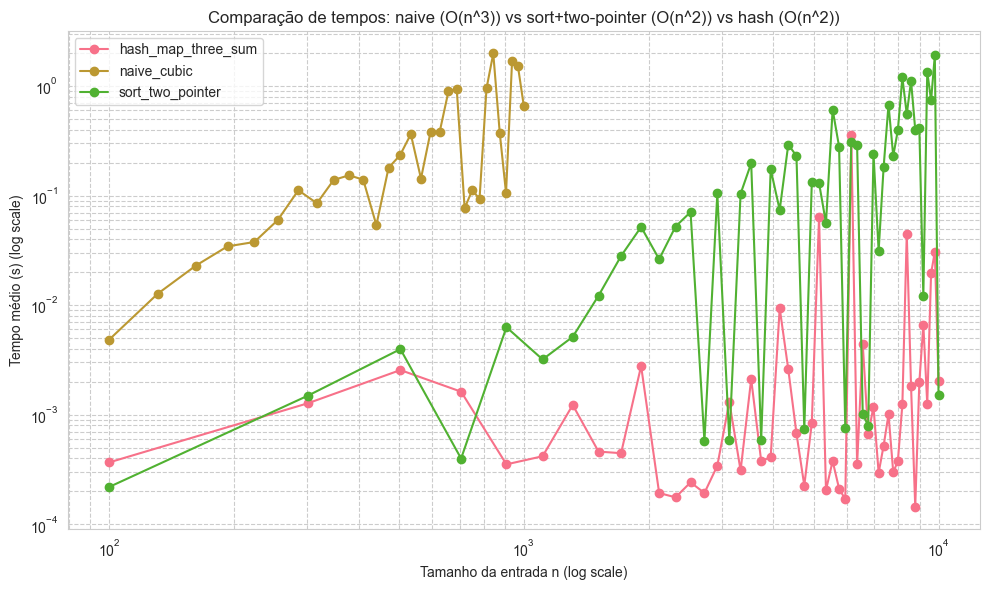

Resultados salvos em three_sum_experiment_results.csv


In [31]:
# ---------------------------------------------------------
# 6) Executando para
# ---------------------------------------------------------

if __name__ == "__main__":
    trials = 5  # Reduzido de 10 para 5

    # Gera tamanhos menores para execução em ~5 minutos
    # Para O(n²): 50 tamanhos de 100 até 10.000
    sizes_opt = np.linspace(100, 10_000, 50, dtype=int)
    
    # Para O(n³): 30 tamanhos de 100 até 1.000
    sizes_naive = np.linspace(100, 1_000, 30, dtype=int)

    df, all_instances = run_experiment(sizes_opt, sizes_naive, trials=trials)
    print(df)

    common = sorted(set(sizes_opt).intersection(set(sizes_naive)))
    if common:
        print("\n== CONSISTÊNCIA ENTRE OS ALGORITMOS ==")
        cons = consistency_check(common, all_instances)
        print(cons)

    plot_results(df)

    df.to_csv("three_sum_experiment_results.csv", index=False)
    print("Resultados salvos em three_sum_experiment_results.csv")